# Denoising Diffusion Probabilistic Model on MNIST

This notebook scales the two-dimensional diffusion example to images by implementing a **basic DDPM** from first principles in PyTorch.

### Learning goals
1. See the fixed **forward process** gradually destroy an MNIST image with Gaussian noise.
2. Understand why the closed-form marginal $q(x_t\mid x_0)$ makes training efficient.
3. Train a time-conditioned convolutional network to predict the added noise.
4. Derive and implement one probabilistic **reverse step** $p_\theta(x_{t-1}\mid x_t)$.
5. Watch a sample evolve from $x_T\sim\mathcal N(0,I)$ back into a digit.

The forward process is not learned. The neural network learns to approximate its time reversal.

## Before you begin

**Prerequisites.** Review Gaussian conditionals, the Markov property, expectation-based regression, and time-conditioned convolutional networks. Notebook 05 (the ring diffusion model) is the conceptual predecessor.

> **Notation and orientation**
> - $x_0$ is a clean image, $x_t$ its noisy state, $\bar\alpha_t=\prod_{s=1}^t(1-\beta_s)$, and $\epsilon_\theta(x_t,t)$ predicts added noise.
> - **Unchanged from the ring:** the fixed forward process, closed-form $q(x_t\mid x_0)$, and iterative learned reverse process.
> - **New at image scale:** a time-conditioned U-Net and spatial denoising of $1\times28\times28$ tensors.

## 1. Setup and configuration

The notebook uses only Python's standard library, NumPy, Matplotlib, and PyTorch. It selects a GPU automatically when available. MNIST pixels are scaled to $[-1,1]$, matching the zero-centered Gaussian diffusion process.

>**Run modes:** `RUN_MODE = "lecture"` (the default) loads the bundled checkpoint and avoids retraining. Use `"full"` to train the documented configuration, or `"smoke"` for a reduced CPU pipeline check. Smoke-mode checkpoints and results are deliberately separate and are **not** representative model results.


In [1]:
import copy
import gzip
import random
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
RUN_MODE = "lecture"  # "lecture", "full", or "smoke"
if RUN_MODE not in {"lecture", "full", "smoke"}:
    raise ValueError("RUN_MODE must be 'lecture', 'full', or 'smoke'.")
TRAIN = RUN_MODE != "lecture"
EPOCHS = 1 if RUN_MODE == "smoke" else 30
BATCH_SIZE = 128
LEARNING_RATE = 2e-4
T = 50 if RUN_MODE == "smoke" else 300
BASE_CHANNELS = 16 if RUN_MODE == "smoke" else 32
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
checkpoint_name = "ddpm_mnist_smoke.pt" if RUN_MODE == "smoke" else "ddpm_mnist.pt"
CHECKPOINT = NOTEBOOK_DIR / "checkpoints" / checkpoint_name
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | run mode: {RUN_MODE}")
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")

PyTorch 2.12.0+cu130 | device: cuda | run mode: lecture


## 2. Download and parse MNIST

MNIST contains 60,000 training and 10,000 test images of handwritten digits. The compressed IDX files are cached under `data/mnist`.

Labels are loaded only to choose recognizable examples. The DDPM itself is **unconditional** and never receives a class label.

In [2]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}

for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        print(f"Downloading {filename} ...")
        urlretrieve(BASE_URL + filename, destination)


def read_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, columns = struct.unpack(">IIII", file.read(16))
        assert magic == 2051
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    images = torch.from_numpy(array.reshape(count, 1, rows, columns)).float() / 255
    return images * 2 - 1


def read_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        assert magic == 2049
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(array.astype(np.int64))


x_train = read_idx_images(DATA_DIR / FILES["train_images"])
y_train = read_idx_labels(DATA_DIR / FILES["train_labels"])
x_test = read_idx_images(DATA_DIR / FILES["test_images"])
y_test = read_idx_labels(DATA_DIR / FILES["test_labels"])

train_count = len(x_train) if RUN_MODE != "smoke" else min(2_048, len(x_train))
train_dataset = TensorDataset(x_train[:train_count])
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)
print(f"Training: {tuple(x_train.shape)} | test: {tuple(x_test.shape)}")

Training: (60000, 1, 28, 28) | test: (10000, 1, 28, 28)


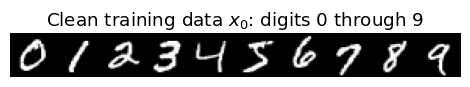

In [3]:
def show_image_grid(images, nrow=10, title=None, value_range=(-1, 1)):
    """Display NCHW or NHW tensors without depending on torchvision."""
    images = images.detach().cpu()
    if images.ndim == 4:
        images = images[:, 0]
    n = len(images)
    ncol = int(np.ceil(n / nrow))
    # Use the same floating dtype as the images. Without dtype=images.dtype,
    # torch.full infers an integer canvas from value_range=(-1, 1), and assigning
    # float images truncates every pixel to -1, 0, or 1 (mostly gray zeros).
    canvas = torch.full(
        (ncol * 28 + (ncol - 1), nrow * 28 + (nrow - 1)),
        fill_value=float(value_range[0]),
        dtype=images.dtype,
    )
    for index, image in enumerate(images):
        row, column = divmod(index, nrow)
        top, left = row * 29, column * 29
        canvas[top : top + 28, left : left + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


train_example_indices = [
    int(torch.where(y_train == digit)[0][0]) for digit in range(10)
]
test_example_indices = [
    int(torch.where(y_test == digit)[0][0]) for digit in range(10)
]
show_image_grid(
    x_train[train_example_indices],
    nrow=10,
    title="Clean training data $x_0$: digits 0 through 9",
)

## 3. Forward diffusion: data becomes noise

The forward Markov chain adds a small amount of Gaussian noise at each step:

$$q(x_t\mid x_{t-1})=\mathcal N\!\left(\sqrt{\alpha_t}x_{t-1},(1-\alpha_t)I\right),
\qquad \alpha_t=1-\beta_t.$$

Repeated Gaussian transitions combine analytically. With $\bar\alpha_t=\prod_{s=1}^t\alpha_s$,

$$q(x_t\mid x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right),$$

so any noise level can be sampled in one operation:

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).$$

The first term is the remaining **signal** and the second is accumulated **noise**. A cosine schedule makes $\bar\alpha_t$ decay smoothly from nearly one to nearly zero. Its final $\beta_T$ is deliberately very large. This can be valid, but it makes correct time indexing in the first reverse step especially important.

For comparison, we also construct the linear schedule from the original DDPM work. Its classic endpoints were designed for 1,000 steps, so they are scaled by $1000/T$ to retain a comparable total amount of corruption when $T=200$. The active model continues to use the cosine schedule. Switching schedules requires retraining because the meaning of each time index changes.

The signal-to-noise ratio at step $t$ is

$$\operatorname{SNR}(t)=\frac{\bar\alpha_t}{1-\bar\alpha_t}.$$

> In the code, zero-based index `t` stores the mathematical step $t+1$. The clean image $x_0$ is handled separately.

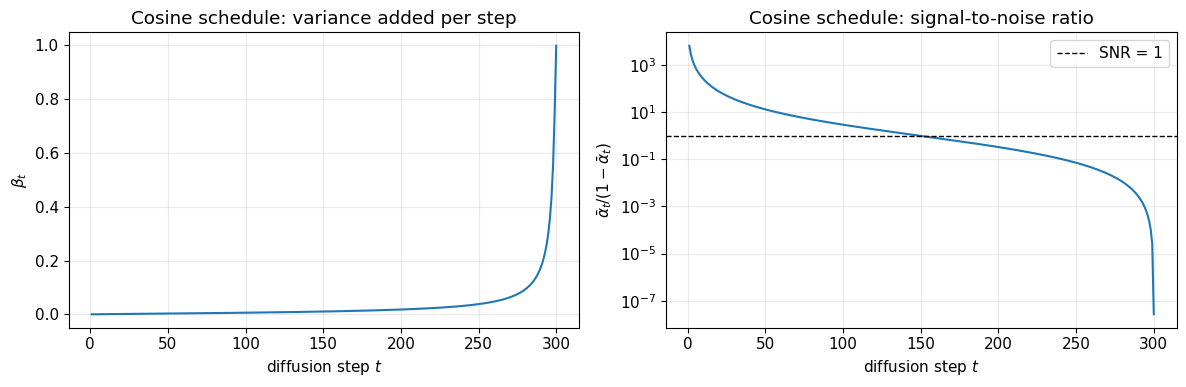

Cosine final signal power: 2.70e-08 | final SNR: 2.70e-08


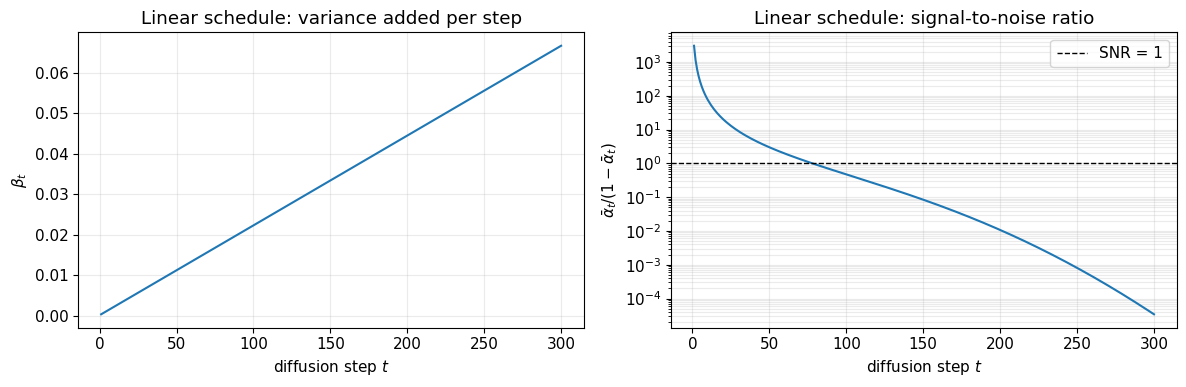

Linear final signal power: 3.43e-05 | final SNR: 3.43e-05


In [4]:
def cosine_beta_schedule(n_steps, offset=0.008):
    """Cosine schedule from Nichol & Dhariwal (2021)."""
    steps = torch.arange(n_steps + 1, dtype=torch.float64)
    f = torch.cos(((steps / n_steps + offset) / (1 + offset)) * torch.pi / 2).square()
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(1e-5, 0.999).float()


def linear_beta_schedule(
    n_steps, beta_start=1e-4, beta_end=2e-2, reference_steps=1_000
):
    """Linear DDPM schedule, rescaled from its original 1,000-step setting."""
    if n_steps < 1:
        raise ValueError("n_steps must be positive")
    scale = reference_steps / n_steps
    start = scale * beta_start
    end = scale * beta_end
    if not 0 < start < end < 1:
        raise ValueError("scaled beta endpoints must satisfy 0 < start < end < 1")
    return torch.linspace(start, end, n_steps, dtype=torch.float32)


def schedule_statistics(schedule_betas):
    """Return cumulative signal power and signal-to-noise ratio."""
    schedule_alpha_bars = torch.cumprod(1 - schedule_betas, dim=0)
    schedule_snr = schedule_alpha_bars / (1 - schedule_alpha_bars)
    return schedule_alpha_bars, schedule_snr


def plot_schedule(schedule_betas, title):
    """Plot per-step variance and cumulative SNR for one schedule."""
    schedule_betas = schedule_betas.detach().cpu()
    schedule_alpha_bars, schedule_snr = schedule_statistics(schedule_betas)
    steps = torch.arange(1, len(schedule_betas) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(steps, schedule_betas)
    axes[0].set(
        xlabel="diffusion step $t$",
        ylabel="$\\beta_t$",
        title=f"{title}: variance added per step",
    )
    axes[0].grid(alpha=0.25)

    axes[1].semilogy(steps, schedule_snr)
    axes[1].axhline(1, color=PLOT_GUIDE_COLOR, linestyle="--", linewidth=1, label="SNR = 1")
    axes[1].set(
        xlabel="diffusion step $t$",
        ylabel="$\\bar\\alpha_t / (1-\\bar\\alpha_t)$",
        title=f"{title}: signal-to-noise ratio",
    )
    axes[1].legend()
    axes[1].grid(alpha=0.25, which="both")
    plt.tight_layout()
    plt.show()
    return schedule_alpha_bars, schedule_snr


# The cosine schedule is active for training and sampling throughout the notebook.
betas = cosine_beta_schedule(T).to(DEVICE)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)


def extract(values, t, target):
    """Gather one schedule value per image and add broadcast dimensions."""
    return values.gather(0, t).reshape(len(t), *([1] * (target.ndim - 1)))


def q_sample(x0, t, noise=None):
    """Draw x_t directly from q(x_t | x_0), without traversing earlier steps."""
    if noise is None:
        noise = torch.randn_like(x0)
    x_t = (
        extract(sqrt_alpha_bars, t, x0) * x0
        + extract(sqrt_one_minus_alpha_bars, t, x0) * noise
    )
    return x_t, noise


# Active cosine schedule.
cosine_alpha_bars, cosine_snr = plot_schedule(betas, "Cosine schedule")
print(
    f"Cosine final signal power: {cosine_alpha_bars[-1].item():.2e} | "
    f"final SNR: {cosine_snr[-1].item():.2e}"
)

# Alternative linear schedule (shown for comparison, but not assigned to `betas`).
linear_betas = linear_beta_schedule(T)
linear_alpha_bars, linear_snr = plot_schedule(linear_betas, "Linear schedule")
print(
    f"Linear final signal power: {linear_alpha_bars[-1].item():.2e} | "
    f"final SNR: {linear_snr[-1].item():.2e}"
)


## 4. Watch the forward process

The same Gaussian noise realization is used at every displayed time. This makes it easy to see the signal coefficient shrink while the noise coefficient grows.

At $t=T$, the image is almost indistinguishable from a standard-normal noise image. No network and no optimization are involved in this forward direction.

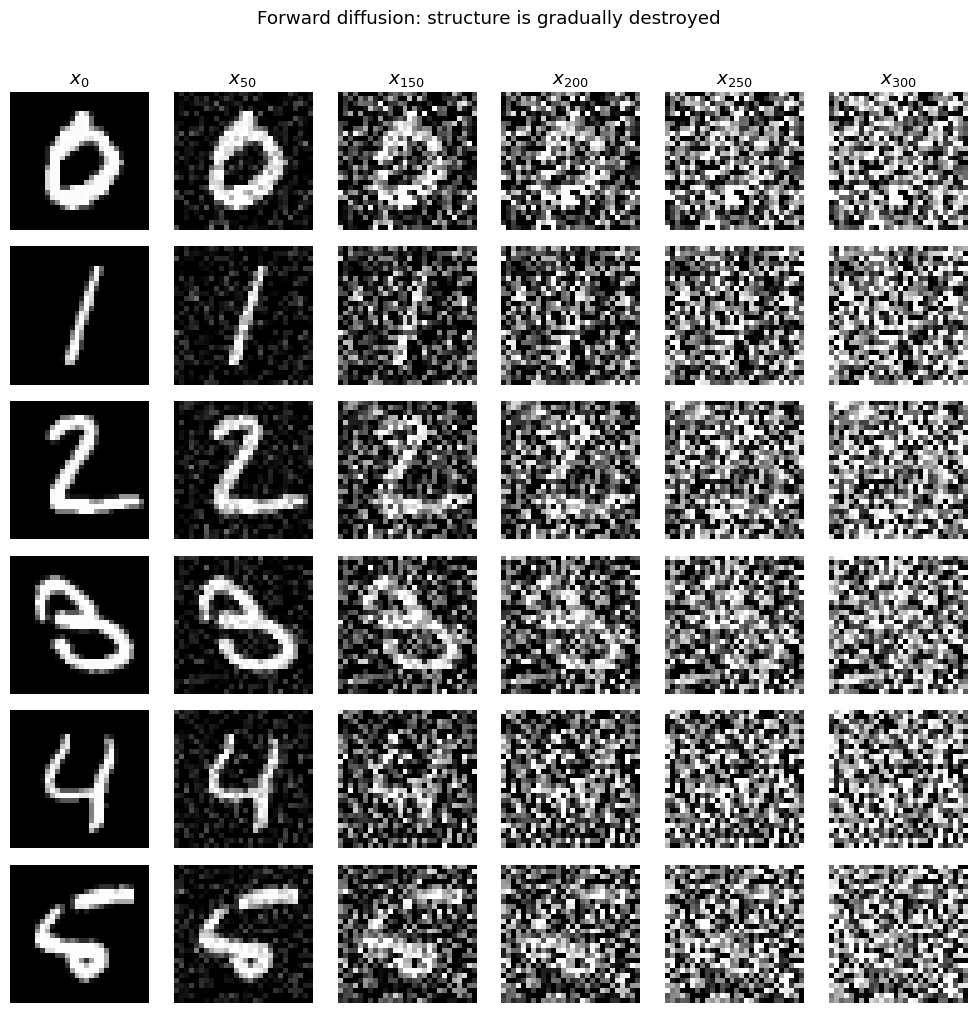

In [5]:
display_steps = [0, 50, 150, 200, 250, 300]
examples = x_test[test_example_indices[:6]].to(DEVICE)
fixed_noise = torch.randn_like(examples)
columns = []
for step in display_steps:
    if step == 0:
        columns.append(examples.cpu())
    else:
        t = torch.full((len(examples),), step - 1, device=DEVICE, dtype=torch.long)
        columns.append(q_sample(examples, t, fixed_noise)[0].cpu())

fig, axes = plt.subplots(len(examples), len(display_steps), figsize=(10, 10))
for row in range(len(examples)):
    for column, step in enumerate(display_steps):
        axes[row, column].imshow(columns[column][row, 0], cmap="gray", vmin=-1, vmax=1)
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title("$x_0$" if step == 0 else f"$x_{{{step}}}$")
plt.suptitle("Forward diffusion: structure is gradually destroyed", y=1.01)
plt.tight_layout()
plt.show()

## 5. One-step chain versus the closed-form jump

The forward process has two equivalent views:

- **Markov view:** repeatedly sample $x_s=\sqrt{\alpha_s}x_{s-1}+\sqrt{\beta_s}z_s$;
- **marginal view:** jump directly to $x_t$ with one accumulated noise variable $\epsilon$.

Individual draws will differ, but both procedures have the same conditional mean and variance. We verify that empirically for many corruptions of one image. Training uses the direct form because it is much faster.

### Predict before running

>**Commit to a prediction:** will an iterative forward chain and a one-shot draw from $q(x_t\mid x_0)$ match pixel by pixel, in distribution, or neither? Justify from the Gaussian marginal.

In [6]:
@torch.no_grad()
def q_sample_iteratively(x0, last_index):
    """Traverse q(x_s | x_{s-1}) up to a zero-based schedule index."""
    x = x0
    for index in range(last_index + 1):
        x = torch.sqrt(alphas[index]) * x + torch.sqrt(betas[index]) * torch.randn_like(x)
    return x


target_index = T // 2 - 1
repeats = 512
repeated_image = x_test[0:1].to(DEVICE).expand(repeats, -1, -1, -1).clone()
iterative = q_sample_iteratively(repeated_image, target_index)
t = torch.full((repeats,), target_index, device=DEVICE, dtype=torch.long)
direct, _ = q_sample(repeated_image, t)
expected_mean = torch.sqrt(alpha_bars[target_index]) * repeated_image
expected_variance = 1 - alpha_bars[target_index]

for name, samples in [("iterative", iterative), ("direct", direct)]:
    mean_error = (samples.mean(0) - expected_mean[0]).abs().mean()
    empirical_variance = samples.var(0, unbiased=False).mean()
    print(
        f"{name:9s} | mean absolute error {mean_error:.4f} | "
        f"variance {empirical_variance:.4f} (theory {expected_variance.item():.4f})"
    )

iterative | mean absolute error 0.0250 | variance 0.5033 (theory 0.5062)
direct    | mean absolute error 0.0248 | variance 0.5044 (theory 0.5062)


>**Expected observation / interpretation.** Independent draws need not match pixel by pixel, but their distributions should agree. The closed form reaches any training time directly, avoiding simulation of all preceding noising steps.

## 6. Learning the reverse direction

A reverse transition should turn $x_t$ into a slightly cleaner $x_{t-1}$. Its exact distribution depends on the unknown clean image distribution, so we learn an approximation:

$$p_\theta(x_{t-1}\mid x_t)=\mathcal N\!\left(\mu_\theta(x_t,t),\tilde\beta_t I\right).$$

Rather than predict the mean directly, a network $\epsilon_\theta(x_t,t)$ predicts the noise that produced $x_t$. The standard simplified DDPM loss is

$$\mathcal L_{\mathrm{simple}}
=\mathbb E_{x_0,t,\epsilon}\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].$$

A single network learns all noise levels. It therefore needs a time embedding, and its output must have the same shape as the input image.

## 7. A small time-conditioned U-Net

The classic denoising U-Net architecture combines:

- convolutions for image structure;
- downsampling for a large receptive field;
- skip connections to preserve spatial detail;
- sinusoidal time features injected into every residual block.

This is intentionally compact. MNIST does not require the attention blocks or very deep U-Nets used by modern high-resolution diffusion models.

In [7]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim % 2 == 0
        frequencies = torch.exp(
            -np.log(10_000) * torch.arange(dim // 2) / (dim // 2 - 1)
        )
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        return torch.cat([angles.sin(), angles.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_features):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(time_features)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SmallUNet(nn.Module):
    def __init__(self, base=32, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base * 2),
            nn.Linear(base * 2, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input = nn.Conv2d(1, base, 3, padding=1)
        self.down1 = ResBlock(base, base, time_dim)             # 28 x 28
        self.downsample1 = nn.Conv2d(base, base * 2, 4, 2, 1)  # 14 x 14
        self.down2 = ResBlock(base * 2, base * 2, time_dim)
        self.downsample2 = nn.Conv2d(base * 2, base * 4, 4, 2, 1)  # 7 x 7
        self.middle1 = ResBlock(base * 4, base * 4, time_dim)
        self.middle2 = ResBlock(base * 4, base * 4, time_dim)
        self.upsample2 = nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1)
        self.up2 = ResBlock(base * 4, base * 2, time_dim)
        self.upsample1 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.up1 = ResBlock(base * 2, base, time_dim)
        self.output = nn.Sequential(
            nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1)
        )

    def forward(self, x, t):
        time_features = self.time_mlp(t)
        x = self.input(x)
        skip1 = self.down1(x, time_features)
        skip2 = self.down2(self.downsample1(skip1), time_features)
        h = self.downsample2(skip2)
        h = self.middle1(h, time_features)
        h = self.middle2(h, time_features)
        h = self.upsample2(h)
        h = self.up2(torch.cat([h, skip2], dim=1), time_features)
        h = self.upsample1(h)
        h = self.up1(torch.cat([h, skip1], dim=1), time_features)
        return self.output(h)


model = SmallUNet(BASE_CHANNELS).to(DEVICE)
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")
with torch.no_grad():
    test_output = model(torch.randn(4, 1, 28, 28, device=DEVICE), torch.arange(4, device=DEVICE))
print("Shape check:", tuple(test_output.shape))

Parameters: 1,244,705
Shape check: (4, 1, 28, 28)


## 8. The complete training example

Each optimization example is constructed independently:

1. draw a clean image $x_0$;
2. draw one time step $t$ uniformly;
3. draw Gaussian noise $\epsilon$;
4. construct $x_t$ directly;
5. regress from $(x_t,t)$ to $\epsilon$.

Training is parallel across random time steps. Unlike generation, it does **not** run the full chain. An exponential moving average (EMA) of the parameters is kept only to make final samples less sensitive to the latest optimizer updates.

In [8]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)
history = []


def update_ema(target, source, decay=0.995):
    with torch.no_grad():
        for target_parameter, source_parameter in zip(target.parameters(), source.parameters()):
            target_parameter.lerp_(source_parameter, 1 - decay)
        for target_buffer, source_buffer in zip(target.buffers(), source.buffers()):
            target_buffer.copy_(source_buffer)


if not TRAIN:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    ema_model.load_state_dict(checkpoint["ema_model"])
    history = checkpoint["history"]
    print(f"Loaded {CHECKPOINT}")
else:
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for (x0,) in train_loader:
            x0 = x0.to(DEVICE, non_blocking=True)
            t = torch.randint(T, (len(x0),), device=DEVICE)
            x_t, noise = q_sample(x0, t)
            predicted_noise = model(x_t, t)
            loss = F.mse_loss(predicted_noise, noise)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            update_ema(ema_model, model)
            total_loss += loss.item() * len(x0)

        average_loss = total_loss / len(train_loader.dataset)
        history.append(average_loss)
        print(f"epoch {epoch:2d}/{EPOCHS} | noise MSE {average_loss:.4f}")
        torch.save(
            {
                "model": model.state_dict(),
                "ema_model": ema_model.state_dict(),
                "history": history,
                "epoch": epoch,
            },
            CHECKPOINT,
        )
    print(f"Training time: {(time.time() - start) / 60:.1f} min")

Loaded checkpoints/ddpm_mnist.pt


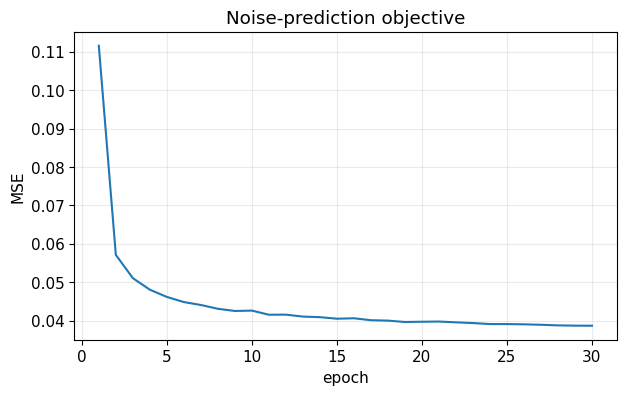

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(history) + 1), history)
ax.set(xlabel="epoch", ylabel="MSE", title="Noise-prediction objective")
ax.grid(alpha=0.25)
plt.show()

## 9. Noise prediction implies clean-image prediction

Rearranging the forward equation gives an estimate of the clean image:

$$\hat x_0(x_t,t)=
\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}.$$

At low and medium noise levels, the network should recover recognizable structure. At very late times, one noisy image is compatible with many possible digits, so a one-shot estimate is uncertain and often blurry. The full reverse chain resolves this ambiguity gradually.

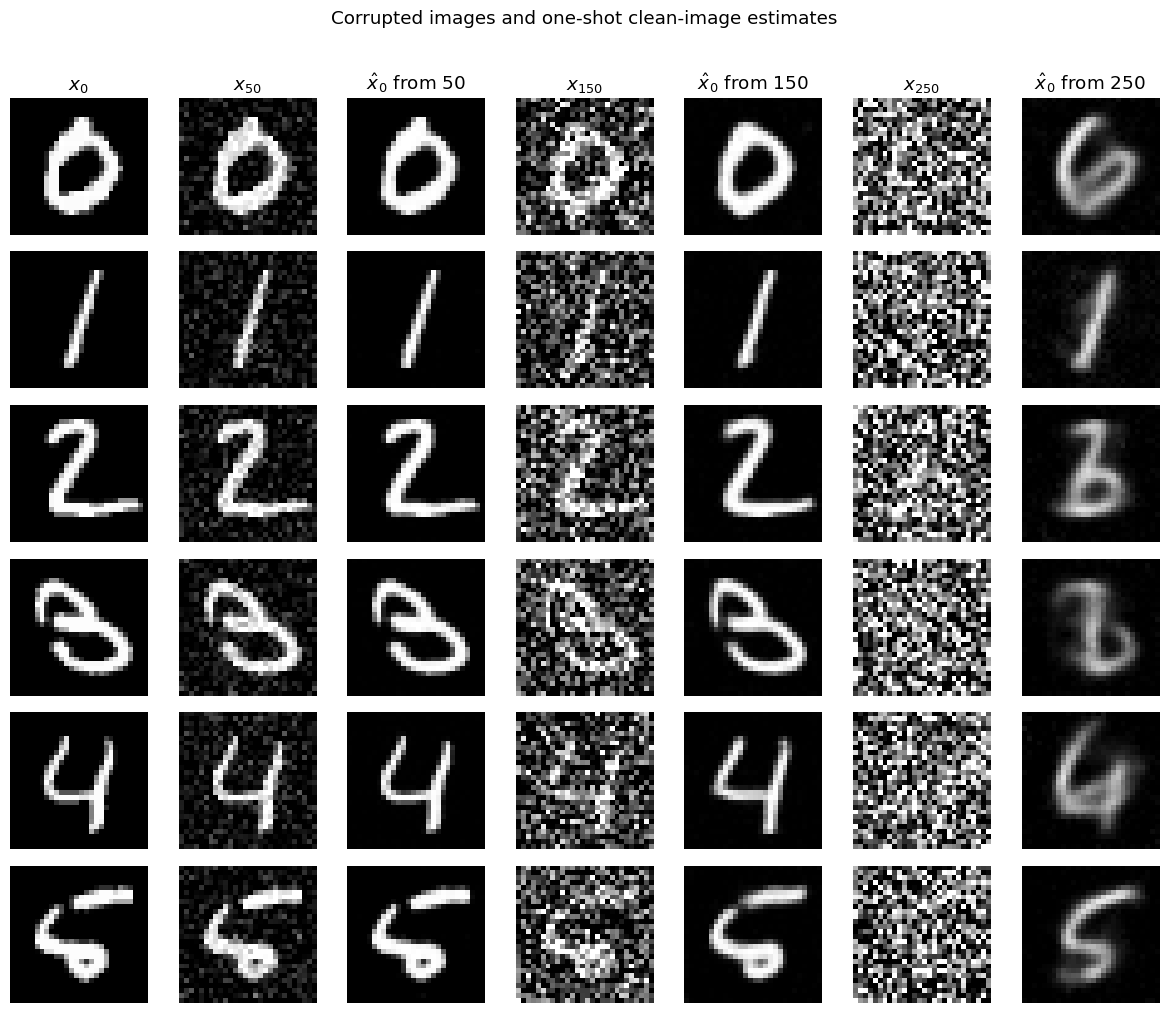

In [10]:
@torch.no_grad()
def predict_x0(model, x_t, t):
    predicted_noise = model(x_t, t)
    return (
        x_t - extract(sqrt_one_minus_alpha_bars, t, x_t) * predicted_noise
    ) / extract(sqrt_alpha_bars, t, x_t)


ema_model.eval()
clean = x_test[test_example_indices[:6]].to(DEVICE)
denoising_steps = [50, 150, 250]
fig, axes = plt.subplots(len(clean), 1 + 2 * len(denoising_steps), figsize=(12, 10))
for row in range(len(clean)):
    axes[row, 0].imshow(clean[row, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    axes[row, 0].axis("off")
    if row == 0:
        axes[row, 0].set_title("$x_0$")

for group, step in enumerate(denoising_steps):
    t = torch.full((len(clean),), step - 1, device=DEVICE, dtype=torch.long)
    noisy, _ = q_sample(clean, t)
    estimate = predict_x0(ema_model, noisy, t).clamp(-1, 1)
    for row in range(len(clean)):
        for offset, images, title in [
            (1, noisy, f"$x_{{{step}}}$"),
            (2, estimate, f"$\\hat x_0$ from {step}"),
        ]:
            ax = axes[row, 2 * group + offset]
            ax.imshow(images[row, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
            ax.axis("off")
            if row == 0:
                ax.set_title(title)
plt.suptitle("Corrupted images and one-shot clean-image estimates", y=1.01)
plt.tight_layout()
plt.show()

## 10. The backward diffusion step

If $x_0$ were known, Gaussian conditioning gives the exact posterior

$$q(x_{t-1}\mid x_t,x_0)=\mathcal N(\tilde\mu_t,\tilde\beta_tI),
\qquad
\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.$$

Substituting the network's noise estimate into its posterior mean yields

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).$$

One backward step therefore:

1. predicts the noise component in the current image;
2. moves to the posterior mean of a slightly cleaner image;
3. adds posterior noise, except in the final step.

The code below clips the reconstructed $\hat x_0$ before evaluating the equivalent posterior-mean formula. This standard stabilization is almost inactive for a trained MNIST model, but prevents an imperfect prediction at a very noisy step from being amplified by the reverse recursion.

Starting at $x_T\sim\mathcal N(0,I)$ and repeating this for $T,T-1,\ldots,1$ is ancestral DDPM sampling.

In [11]:
alpha_bars_previous = torch.cat([torch.ones(1, device=DEVICE), alpha_bars[:-1]])
posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)
posterior_mean_coefficient_x0 = (
    betas * torch.sqrt(alpha_bars_previous) / (1 - alpha_bars)
)
posterior_mean_coefficient_xt = (
    torch.sqrt(alphas) * (1 - alpha_bars_previous) / (1 - alpha_bars)
)


@torch.no_grad()
def p_sample(model, x_t, t_index):
    """Sample one transition p_theta(x_{t-1} | x_t)."""
    t = torch.full((len(x_t),), t_index, device=DEVICE, dtype=torch.long)
    predicted_noise = model(x_t, t)
    predicted_x0 = (
        x_t - sqrt_one_minus_alpha_bars[t_index] * predicted_noise
    ) / sqrt_alpha_bars[t_index]
    predicted_x0 = predicted_x0.clamp(-1, 1)

    # This posterior-mean form is algebraically equivalent to the epsilon form above,
    # while making the roles of the predicted clean image and current state explicit.
    mean = (
        posterior_mean_coefficient_x0[t_index] * predicted_x0
        + posterior_mean_coefficient_xt[t_index] * x_t
    )
    if t_index == 0:
        return mean
    return mean + torch.sqrt(posterior_variance[t_index]) * torch.randn_like(x_t)


@torch.no_grad()
def sample_ddpm(model, n_images, snapshot_steps=()):
    """Run the complete reverse chain and optionally retain intermediate states."""
    model.eval()
    x = torch.randn(n_images, 1, 28, 28, device=DEVICE)
    snapshots = {T: x.cpu()} if T in snapshot_steps else {}
    for t_index in reversed(range(T)):
        x = p_sample(model, x, t_index)
        current_step = t_index  # The returned state is x_{t_index}; zero denotes x_0.
        if current_step in snapshot_steps:
            snapshots[current_step] = x.cpu()
    return x.cpu(), snapshots


## 11. Watch noise become digits

The display below runs one complete learned reverse chain. Columns are ordered from $x_T$ on the left to $x_0$ on the right.

Unlike the forward montage, these images do not have a known clean target. Coarse digit identity appears first; later steps sharpen strokes and suppress residual noise.

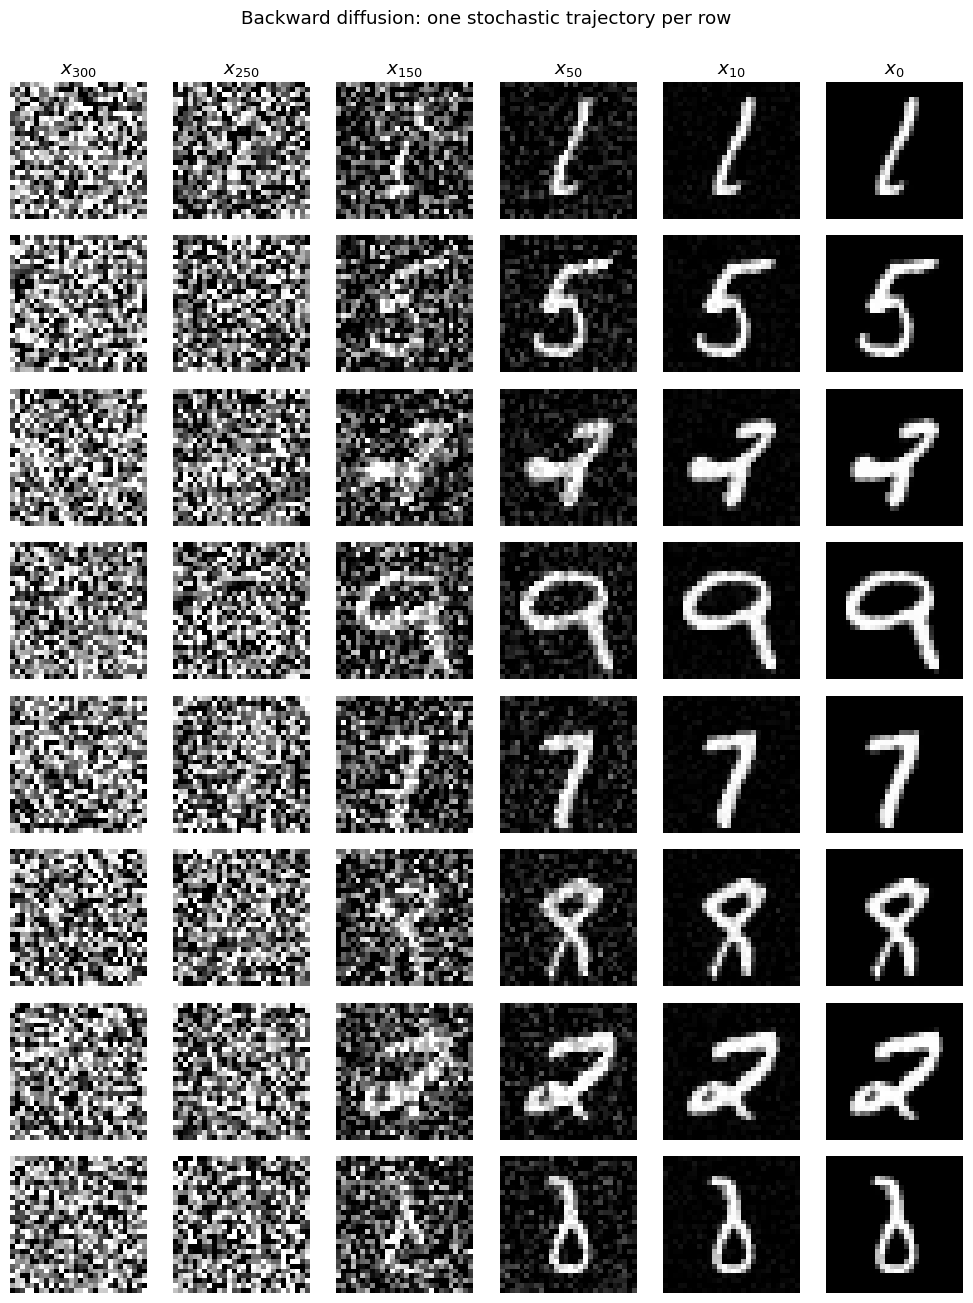

In [12]:
snapshot_steps = [T, 250, 150, 50, 10, 0]
generated_small, reverse_snapshots = sample_ddpm(
    ema_model, n_images=8, snapshot_steps=snapshot_steps
)

fig, axes = plt.subplots(8, len(snapshot_steps), figsize=(10, 13))
for row in range(8):
    for column, step in enumerate(snapshot_steps):
        image = reverse_snapshots[step][row, 0]
        axes[row, column].imshow(image, cmap="gray", vmin=-1, vmax=1)
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(f"$x_{{{step}}}$")
plt.suptitle("Backward diffusion: one stochastic trajectory per row", y=1.0)
plt.tight_layout()
plt.show()

## 12. Unconditional samples

Every image begins as an independent standard-normal tensor. Generation requires $T$ sequential network evaluations, which is the main computational cost of a basic DDPM.

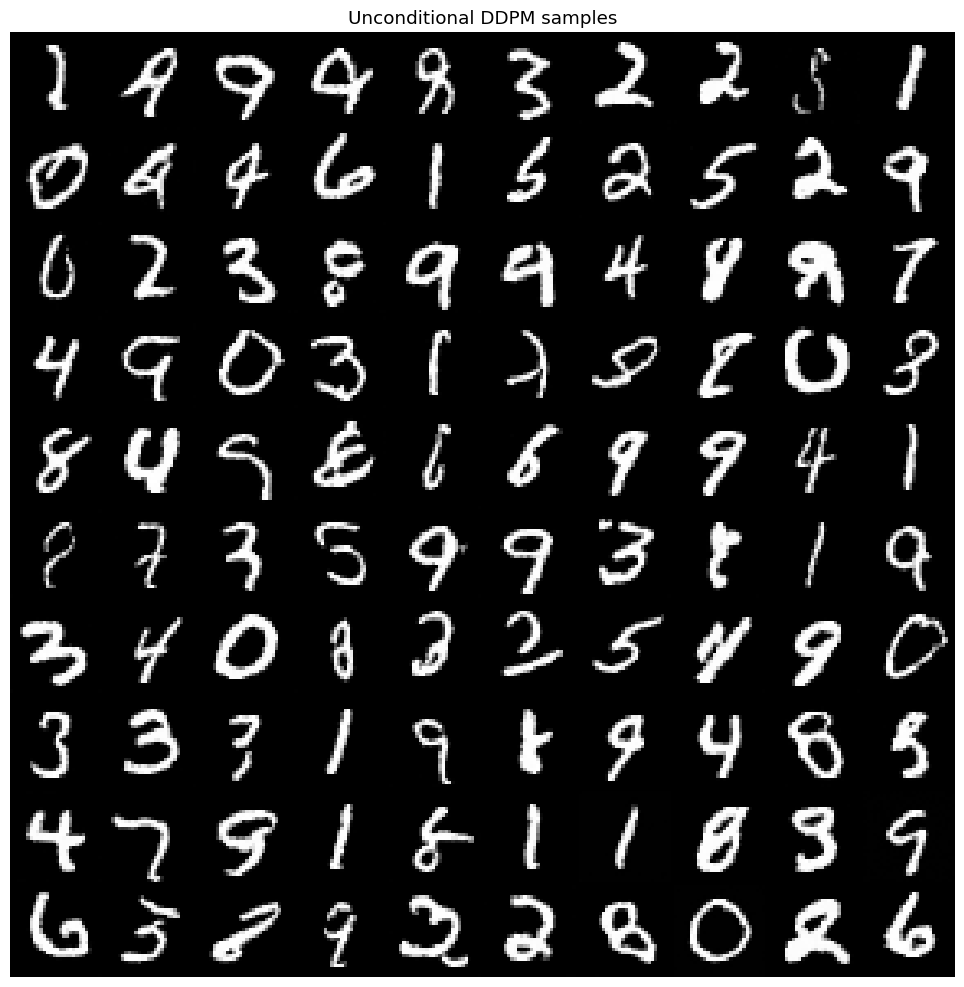

In [13]:
generated, _ = sample_ddpm(ema_model, n_images=100)
show_image_grid(generated, nrow=10, title="Unconditional DDPM samples")

## 13. Where reverse-process randomness enters

Ancestral DDPM sampling injects fresh Gaussian noise at every reverse step except the last. To make that stochasticity visible without a misleading setup, we compare two trajectories that share the same state at $x_{150}$ and then use independent random draws for the remaining transitions.

The shared $x_{150}$ already contains substantial digit structure, so the continuations should preserve its broad identity while differing in fine stroke details. Starting ten chains from an identical $x_T$ is not a useful demonstration here: with a cosine schedule, the first reverse transition has an unusually large variance and immediately separates those trajectories.

### Predict before running

>**Commit to a prediction:** for two reverse trajectories starting from the same $x_T$, at which steps can they diverge, and what should happen at the final step? Justify from the posterior variance term.

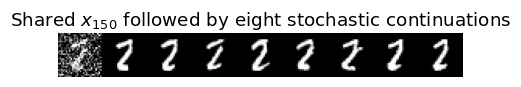

In [16]:
SHARED_T = 150

@torch.no_grad()
def continue_from_state(model, state, start_step, n_repeats=8):
    """Continue independent reverse chains from a shared x_start_step."""
    x = state.expand(n_repeats, -1, -1, -1).clone()
    for t_index in reversed(range(start_step)):
        x = p_sample(model, x, t_index)
    return x.cpu()


# First construct one state x_100, then branch the reverse trajectory.
with torch.no_grad():
    shared_state = torch.randn(1, 1, 28, 28, device=DEVICE)
    for t_index in reversed(range(SHARED_T, T)):
        shared_state = p_sample(ema_model, shared_state, t_index)

stochastic_continuations = continue_from_state(
    ema_model, shared_state, start_step=SHARED_T, n_repeats=8
)
show_image_grid(
    torch.cat([shared_state.cpu(), stochastic_continuations]),
    nrow=9,
    title=f"Shared $x_{{{SHARED_T}}}$ followed by eight stochastic continuations",
)

>**Expected observation / interpretation.** Trajectories diverge wherever nonzero posterior noise is injected. The final transition uses no additional noise, but earlier random choices have already changed the state. Reverse randomness therefore yields multiple plausible paths from one initial latent.

## 14. Forward and backward diffusion at a glance

| Forward diffusion $q$ | Backward diffusion $p_\theta$ |
|---|---|
| Data $\rightarrow$ noise | Noise $\rightarrow$ data |
| Fixed. No learned parameters | Learned noise predictor |
| Markov transitions are known Gaussians | Reverse transitions are approximated Gaussians |
| Any $x_t$ is available directly during training | All steps are traversed sequentially during sampling |
| Destroys information | Reconstructs statistically plausible structure |

The model does not memorize an exact inverse of each forward trajectory. Near $x_T$, most information about the original image has been destroyed. It instead learns the statistics needed to turn random noise into a new sample from the data distribution.

## 15. Takeaways and homework experiments

### Takeaways
- The forward process is fixed, tractable, and has a closed-form marginal $q(x_t\mid x_0)$.
- A time-conditioned U-Net learns to predict noise at every corruption level.
- Noise prediction can be rearranged into clean-image prediction and the DDPM reverse mean.
- Training samples independent random time steps and is parallel; generation is an iterative reverse chain.
- A basic DDPM has a stable regression objective and good coverage, but sampling is slow.

### Mini-experiment 1 — Cosine versus linear forward schedules
- **Hypothesis:** A linear $\beta_t$ schedule allocates signal destruction differently, so the same display times will not have the same visual signal-to-noise progression.
- **Metric/plot:** Compare forward montages and plot $\bar\alpha_t$ or log-SNR against $t$ for both schedules.
- **Controls:** Use the same clean images, Gaussian noise seeds, $T$, and display times.
- **Interpretation:** Explain differences through retained signal, not denoiser quality. 

### Mini-experiment 2 — Deterministic versus ancestral reverse updates
- **Hypothesis:** Setting posterior noise to zero reduces trajectory diversity for fixed $x_T$ and may alter quality because the checkpoint was trained for the DDPM reverse chain.
- **Metric/plot:** From repeated identical $x_T$, plot conditional RMS spread and show matched output grids with noise on/off.
- **Controls:** Reuse the same checkpoint, initial noise, schedule, seeds, and number of reverse steps.
- **Interpretation:** Distinguish randomness removed during reversal from randomness already present in $x_T$. 

### Extensions
- Remove the time embedding and observe why one denoiser cannot treat every noise level identically.
- Reduce `T` to 50 and compare speed and quality after retraining.
- Train longer or widen the U-Net and inspect fine stroke quality.

## Exit ticket

1. Why does the closed-form $q(x_t\mid x_0)$ make DDPM training efficient?
<details><summary>Self-check</summary>It samples any random training time directly instead of simulating all earlier forward transitions.</details>

2. Why must the denoiser receive $t$?
<details><summary>Self-check</summary>The meaning and scale of corruption change with time, so one network must know which denoising problem it is solving.</details>

3. Where does reverse-process randomness enter, and why can fixed $x_T$ yield different outputs?
<details><summary>Self-check</summary>Gaussian noise is added at reverse steps with nonzero posterior variance. Different draws create different trajectories from the same initial latent.</details>

## References and further reading

- [Ho, Jain & Abbeel, “Denoising Diffusion Probabilistic Models” (NeurIPS 2020)](https://proceedings.neurips.cc/paper/2020/hash/4c5bcfec8584af0d967f1ab10179ca4b-Abstract.html): Foundational DDPM objective and reverse-process construction implemented here.
- [Nichol & Dhariwal, “Improved Denoising Diffusion Probabilistic Models” (ICML 2021)](https://proceedings.mlr.press/v139/nichol21a.html): Explains the cosine schedule and practical improvements relevant to this notebook.